# 04-Expériences : époques locales et fraction de clients

In [1]:
import sys
sys.path.append("..")

import json
import time
import matplotlib.pyplot as plt
from src.data import load_mnist, split_iid
from src.server import run_fedavg

train, test = load_mnist()
clients = split_iid(train, n_clients=10)
n_rounds = 10

In [2]:
# A : époques locales, tous les clients
exp_a = {}
for e in [1, 2, 5]:
    t = time.time()
    exp_a[e] = run_fedavg(clients, test, n_rounds, local_epochs=e, frac=1.0)
    print(f"E={e} : finale {exp_a[e][-1]:.4f} ({time.time() - t:.0f}s)")

E=1 : finale 0.9363 (121s)


E=2 : finale 0.9646 (252s)


E=5 : finale 0.9813 (612s)


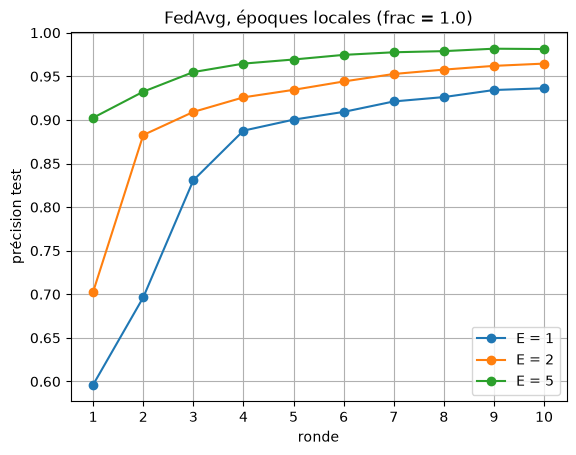

In [3]:
x = range(1, n_rounds + 1)
for e, accs in exp_a.items():
    plt.plot(x, accs, marker="o", label=f"E = {e}")
plt.xlabel("ronde")
plt.ylabel("précision test")
plt.title("FedAvg, époques locales (frac = 1.0)")
plt.xticks(x)
plt.legend()
plt.grid(True)
plt.savefig("../results/exp_epoques_locales.png")
plt.show()

with open("../results/exp_epoques_locales.json", "w") as f:
    json.dump(exp_a, f)

In [4]:
# B : fraction de clients par ronde, 1 époque locale
exp_b = {}
for frac in [0.1, 0.5, 1.0]:
    t = time.time()
    exp_b[frac] = run_fedavg(clients, test, n_rounds, local_epochs=1, frac=frac)
    print(f"frac={frac} : finale {exp_b[frac][-1]:.4f} ({time.time() - t:.0f}s)")

frac=0.1 : finale 0.9336 (27s)


frac=0.5 : finale 0.9362 (77s)


frac=1.0 : finale 0.9363 (141s)


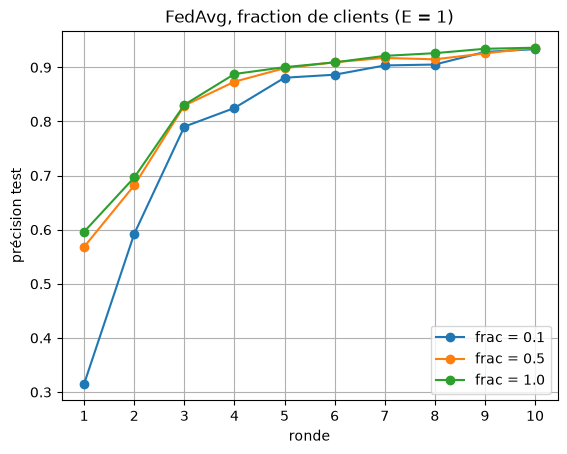

In [5]:
for frac, accs in exp_b.items():
    plt.plot(x, accs, marker="o", label=f"frac = {frac}")
plt.xlabel("ronde")
plt.ylabel("précision test")
plt.title("FedAvg, fraction de clients (E = 1)")
plt.xticks(x)
plt.legend()
plt.grid(True)
plt.savefig("../results/exp_fraction_clients.png")
plt.show()

with open("../results/exp_fraction_clients.json", "w") as f:
    json.dump(exp_b, f)